# 1. 데이터 확인 · 전처리 · 시각화 (EDA)

이 노트북은 DACON 와인 품질 분류 데이터의 구조를 확인하고, 그 결과를 바탕으로 모델링 단계의 결정을 내린 과정을 담는다. 각 관찰이 어떤 결정으로 이어졌는지는 아래 표와 같다.

| 이 노트북에서 확인한 사실 | 그래서 모델링에서 내린 결정 |
|---|---|
| 결측치가 없고, `index`는 식별 번호이며 `type`(종류)만 문자형이다 | `index`를 제거하고 종류를 숫자(화이트=1)로 바꾼 뒤 레드·화이트를 한 모델로 학습한다 |
| 학습 데이터에 성분이 완전히 같은 행이 858개(15.6%) 있고, 성분이 같으면 품질도 항상 같다(충돌 0건) | 교차검증에서 같은 성분의 와인을 한 묶음으로 두는 그룹 교차검증을 쓴다. 일반 5-Fold 0.6765가 그룹 교차검증에서는 0.5758로 내려가, 중복 행이 점수를 약 0.10 부풀렸음을 확인했다 |
| 테스트 1,000행 중 303행은 학습 데이터와 성분이 같다 | 이 303행은 모델 예측 대신 학습 데이터의 품질을 그대로 쓴다. 따라서 리더보드 점수는 처음 보는 697행의 정확도로 결정된다 |
| 품질은 5~7등급에 90% 이상 몰려 있고 3·9등급은 매우 적다 | 등급 비율을 유지하는 층화 분할을 쓰고, 정확도는 주로 5·6·7등급 구분에서 결정된다고 보고 모델을 비교한다 |
| 학습·테스트의 성분 평균과 분포, 종류 비율이 거의 같다 | 학습 데이터로 검증한 결과가 테스트에도 그대로 적용된다고 보고 별도의 분포 보정을 하지 않는다 |
| 염화물·황산염 등은 오른쪽으로 꼬리가 긴 분포이고, 이상치의 대부분이 레드 와인이다 | 값의 크기 순서만 쓰는 트리 모델은 이런 분포에 영향을 거의 받지 않으므로 로그 변환·이상치 제거를 하지 않는다 |
| 등급이 높을수록 도수는 오르고 밀도·휘발성산·염화물은 내려가지만, 인접 등급(5·6·7)의 분포는 크게 겹친다 | 한 변수의 기준선으로는 등급을 나눌 수 없으므로, 여러 성분의 조합을 학습하는 트리 앙상블 모델을 중심으로 한다 |
| 결합 이산화황(bound_so2) 등 파생 변수는 그룹 교차검증에서 효과가 없었다 | 파생 변수는 팀 공통 전처리에 포함된 bound_so2만 일부 모델에 남기고 새 파생 변수는 추가하지 않는다 |

모델 구성과 그 이유는 [`02_model_0711.ipynb`](02_model_0711.ipynb)에서 설명한다.

In [25]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
train=pd.read_csv('/content/drive/MyDrive/train.csv')
test=pd.read_csv('/content/drive/MyDrive/test.csv')

In [27]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5497 entries, 0 to 5496
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 5497 non-null   int64  
 1   quality               5497 non-null   int64  
 2   fixed acidity         5497 non-null   float64
 3   volatile acidity      5497 non-null   float64
 4   citric acid           5497 non-null   float64
 5   residual sugar        5497 non-null   float64
 6   chlorides             5497 non-null   float64
 7   free sulfur dioxide   5497 non-null   float64
 8   total sulfur dioxide  5497 non-null   float64
 9   density               5497 non-null   float64
 10  pH                    5497 non-null   float64
 11  sulphates             5497 non-null   float64
 12  alcohol               5497 non-null   float64
 13  type                  5497 non-null   object 
dtypes: float64(11), int64(2), object(1)
memory usage: 601.4+ KB


In [28]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 1000 non-null   int64  
 1   fixed acidity         1000 non-null   float64
 2   volatile acidity      1000 non-null   float64
 3   citric acid           1000 non-null   float64
 4   residual sugar        1000 non-null   float64
 5   chlorides             1000 non-null   float64
 6   free sulfur dioxide   1000 non-null   float64
 7   total sulfur dioxide  1000 non-null   float64
 8   density               1000 non-null   float64
 9   pH                    1000 non-null   float64
 10  sulphates             1000 non-null   float64
 11  alcohol               1000 non-null   float64
 12  type                  1000 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 101.7+ KB


=> 결측치 x
=> index 컬럼 드랍

In [29]:
train.select_dtypes(include='object').columns

Index(['type'], dtype='object')

#전처리

In [30]:
train = train.drop(columns='index')
test = test.drop(columns='index')


from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
train['type'] = encoder.fit_transform(train['type'])
test['type'] = encoder.transform(test['type'])

encoder.classes_

array(['red', 'white'], dtype=object)

#EDA

## **중복 데이터 확인**
### **실행 목적**
1. 교차검증 점수 부풀림 방지
2. 모델 비교 결과의 해석 근거
3. 라벨 일관성 확인

- 중복 행이 교차 검증의 학습 fold와 검증 fold에 동시에 포함되면 검증 정확도가 실제보다 높게 추정될 수 있으므로, 모델 평가 시 이를 고려해야 한다.

In [31]:
features = train.columns.drop(['quality', 'type'])

duplicate_count = train.duplicated().sum()
overlap_count = len(test.merge(train.drop_duplicates(), on=list(test.columns)))

print(f'train 중복 행: {duplicate_count}개 ({duplicate_count / len(train) * 100:.1f}%)')
print(f'test 중 train과 같은 행: {overlap_count}개')

train 중복 행: 858개 (15.6%)
test 중 train과 같은 행: 303개


In [32]:
conflict_count = (train.groupby(list(features) + ['type'])['quality'].nunique() > 1).sum()
print(f'성분은 같고 품질이 다른 경우: {conflict_count}건')

성분은 같고 품질이 다른 경우: 0건


같은 행이 학습·검증에 동시에 들어가지 않게 함 (GroupKFold 또는 중복 제거 후 교차검증)

## **품질 등급 분포**

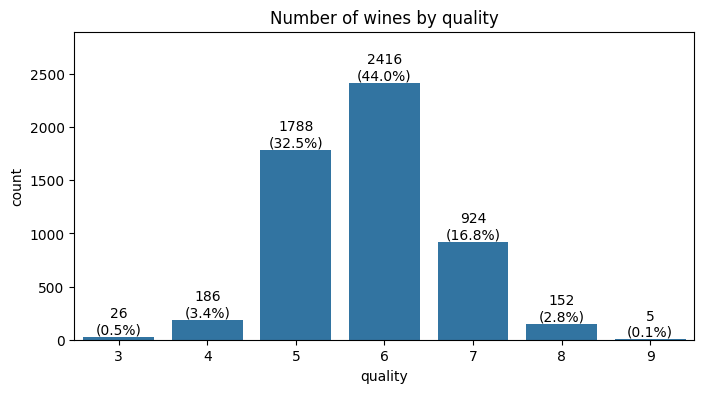

In [33]:
quality_counts = train['quality'].value_counts().sort_index()
quality_ratio = (quality_counts / len(train) * 100).round(1)

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=train, x='quality')
ax.bar_label(ax.containers[0], labels=[f'{c}\n({r}%)' for c, r in zip(quality_counts, quality_ratio)])
ax.set_ylim(0, quality_counts.max() * 1.2)
plt.title('Number of wines by quality')
plt.show()

-> 등급 5~7에서 분포가 90% 이상이 몰려있음


#train test 분포 비교

In [34]:
compare = pd.DataFrame({'train_mean': train[features].mean(), 'test_mean': test[features].mean()})
compare['diff(%)'] = ((compare['test_mean'] / compare['train_mean'] - 1) * 100).round(1)
compare.round(3)

,train_mean,test_mean,diff(%)
fixed acidity,7.210,7.244,0.5
volatile acidity,0.338,0.348,2.9
citric acid,0.319,0.319,0.2
residual sugar,5.438,5.472,0.6
chlorides,0.056,0.057,2.6
free sulfur dioxide,30.418,31.117,2.3
total sulfur dioxide,115.566,116.724,1.0
density,0.995,0.995,0.0
pH,3.220,3.213,-0.2
sulphates,0.531,0.535,0.9


In [35]:
pd.DataFrame({'train': train['type'].value_counts(normalize=True),
              'test': test['type'].value_counts(normalize=True)}).round(3)

,train,test
type,,
1,0.757,0.739
0,0.243,0.261


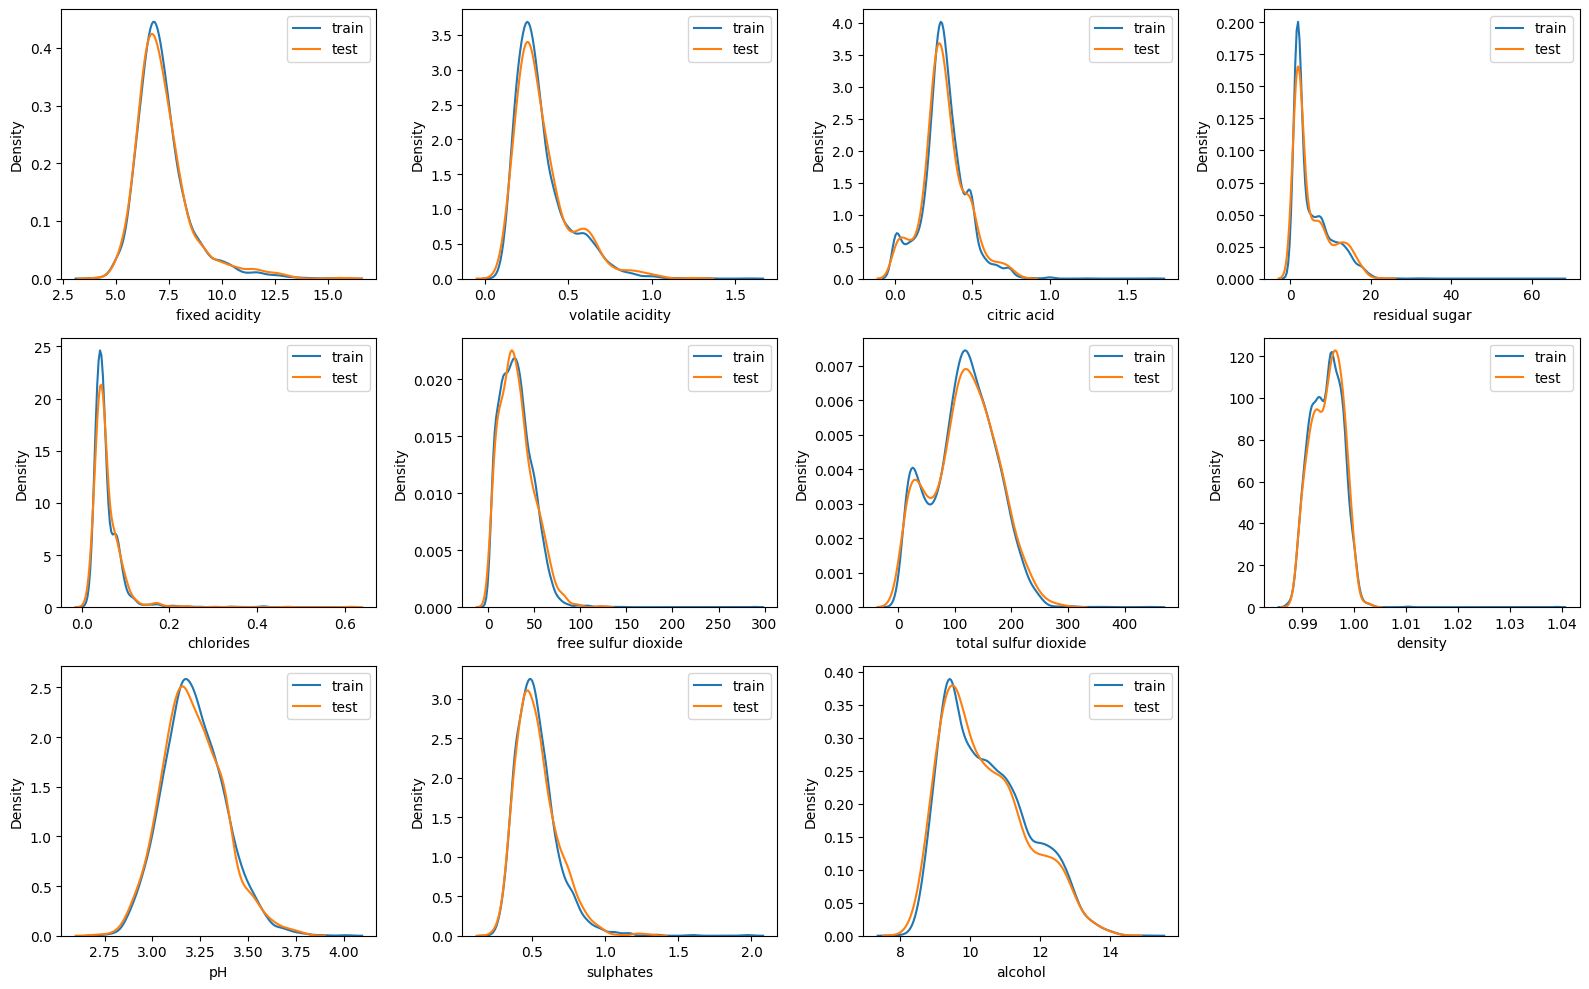

In [36]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(train[col], ax=ax, label='train')
    sns.kdeplot(test[col], ax=ax, label='test')
    ax.legend()
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

## 변수별 분포

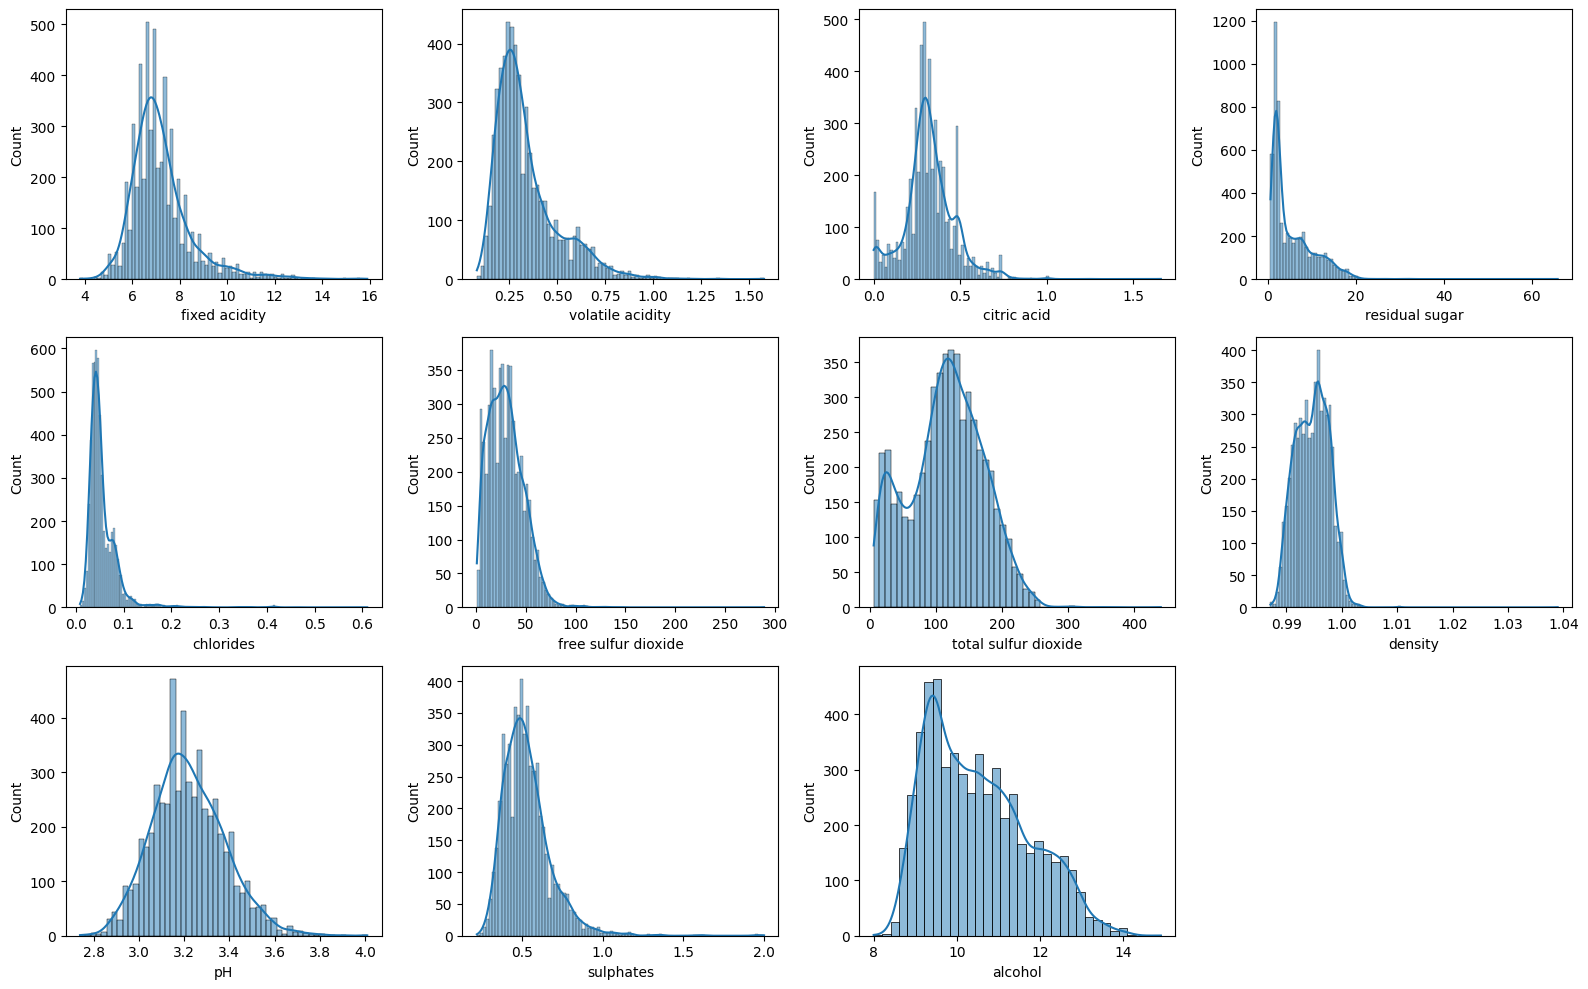

In [37]:
# train의 각 변수별 분포를 살펴봅니다.
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.histplot(train[col], kde=True, ax=ax)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

In [38]:
from scipy.stats import skew

skew_features = train[features].apply(lambda x: skew(x))
skew_features_top = skew_features[skew_features > 1]
print(skew_features_top.sort_values(ascending=False))

chlorides              5.185911
sulphates              1.914956
fixed acidity          1.710430
residual sugar         1.498545
volatile acidity       1.497435
free sulfur dioxide    1.310273
dtype: float64


In [39]:
skew_cols = skew_features_top.index
q1 = train[skew_cols].quantile(0.25)
q3 = train[skew_cols].quantile(0.75)
iqr = q3 - q1
outlier = (train[skew_cols] < q1 - 1.5 * iqr) | (train[skew_cols] > q3 + 1.5 * iqr)

pd.DataFrame({'outlier_count': outlier.sum(),
              'outlier_pct': (outlier.mean() * 100).round(1),
              'red_pct_in_outlier': [(train.loc[outlier[c], 'type'] == 0).mean().round(3) * 100 for c in skew_cols]})

,outlier_count,outlier_pct,red_pct_in_outlier
fixed acidity,294,5.3,91.2
volatile acidity,314,5.7,90.4
residual sugar,106,1.9,0.0
chlorides,259,4.7,65.3
free sulfur dioxide,47,0.9,0.0
sulphates,161,2.9,80.7


#변수 간 상관관계

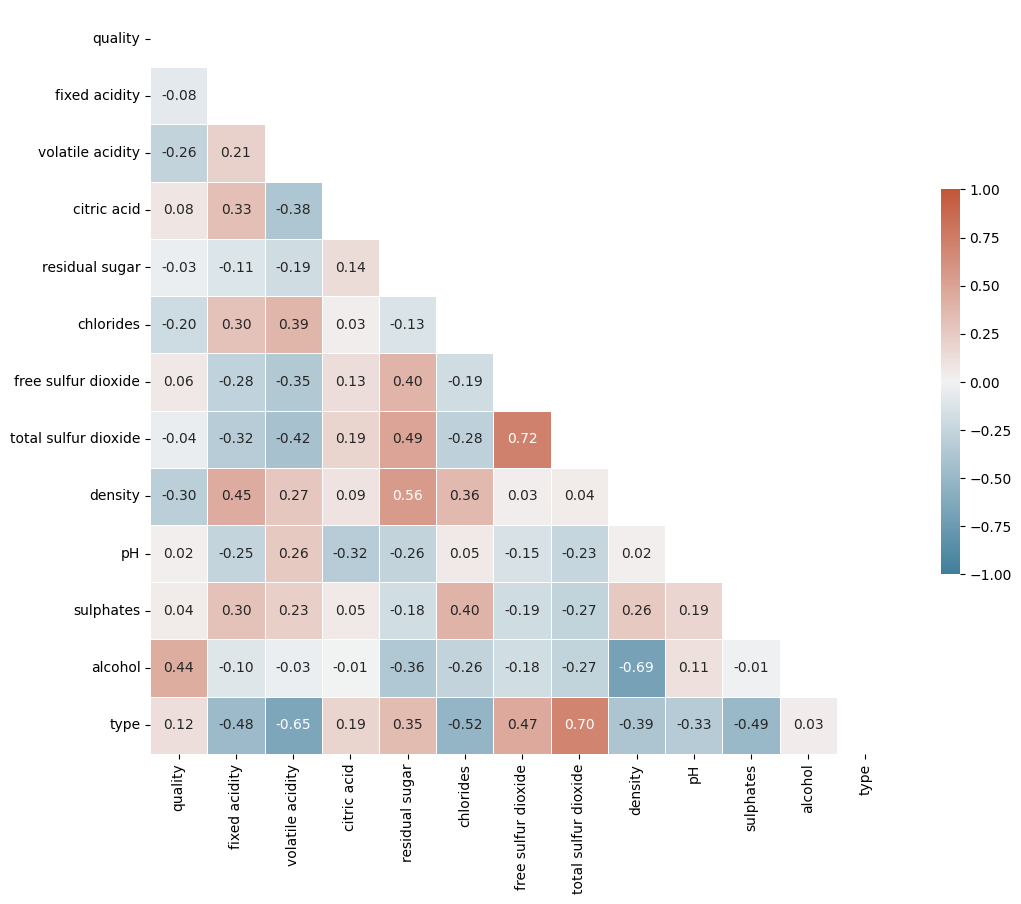

In [40]:
corr = train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

# 등급별 차이



## 등급별 박스플롯

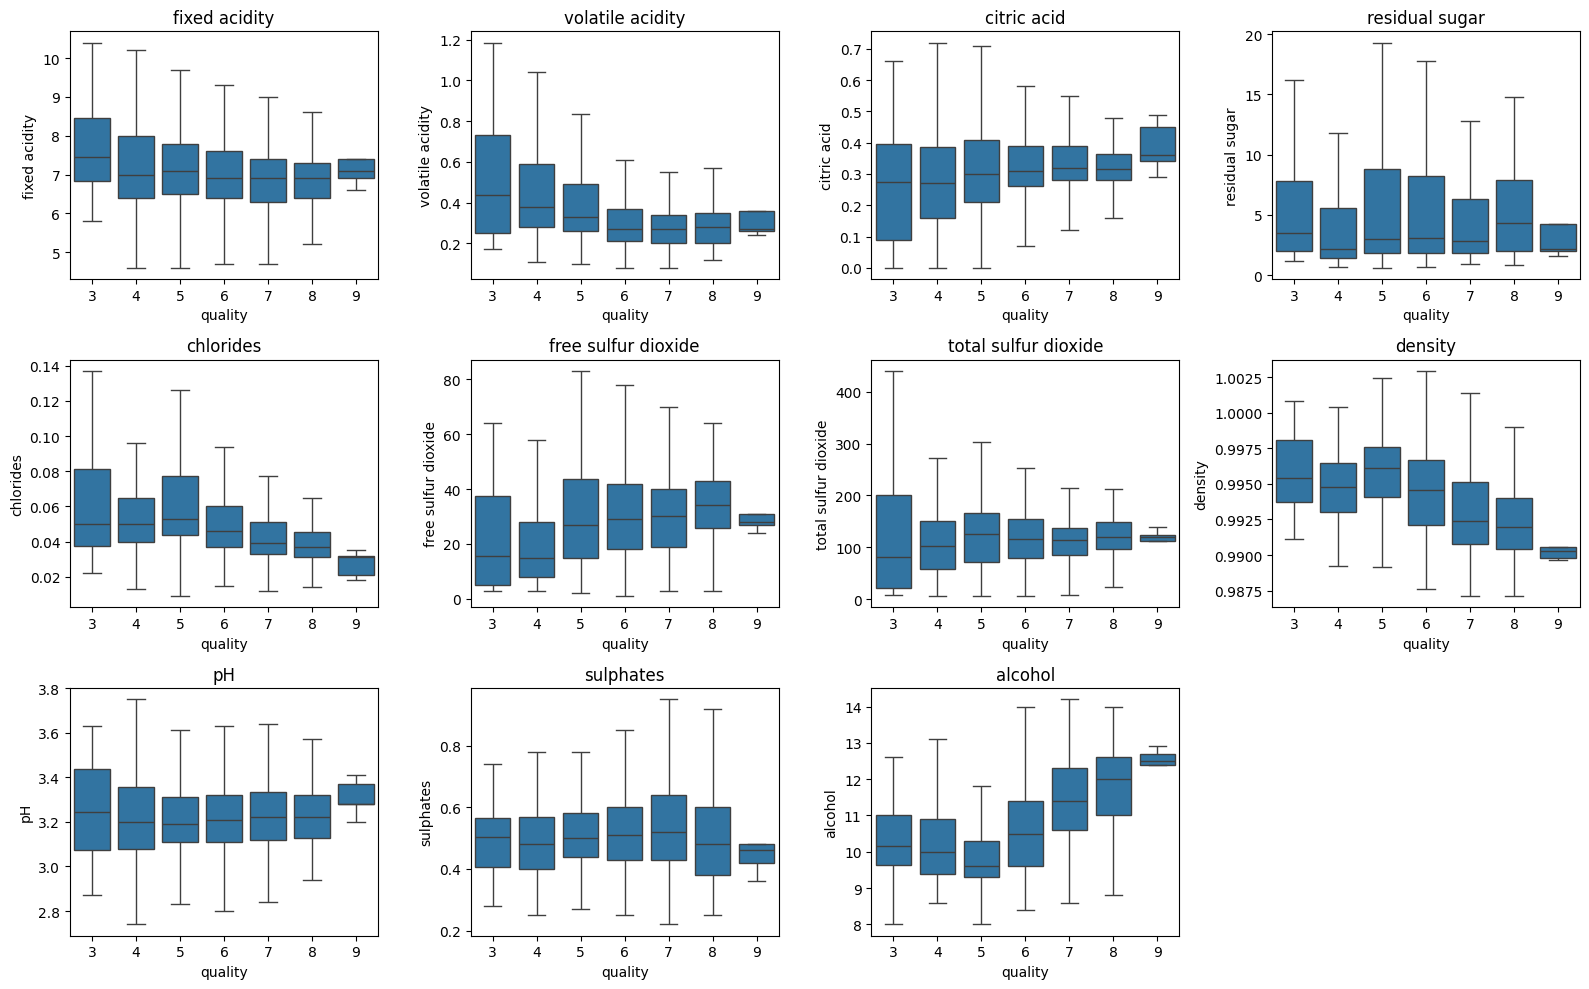

In [41]:
# train에서 각 변수와 quality 변수 사이 분포를 확인합니다.
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=train, x='quality', y=col, ax=ax, showfliers=False)
    ax.set_title(col)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

##등급별 중앙값 표

In [42]:
key_features = ['alcohol', 'density', 'volatile acidity', 'chlorides']

grade_median = train.groupby('quality')[key_features].median()
grade_median['count'] = train['quality'].value_counts().sort_index()
grade_median

,alcohol,density,volatile acidity,chlorides,count
quality,,,,,
3,10.15,0.99540,0.435,0.050,26
4,10.00,0.99480,0.380,0.050,186
5,9.60,0.99610,0.330,0.053,1788
6,10.50,0.99460,0.270,0.046,2416
7,11.40,0.99240,0.270,0.039,924
8,12.00,0.99196,0.280,0.037,152
9,12.50,0.99030,0.270,0.031,5


#와인 종류 × 등급별 박스플롯

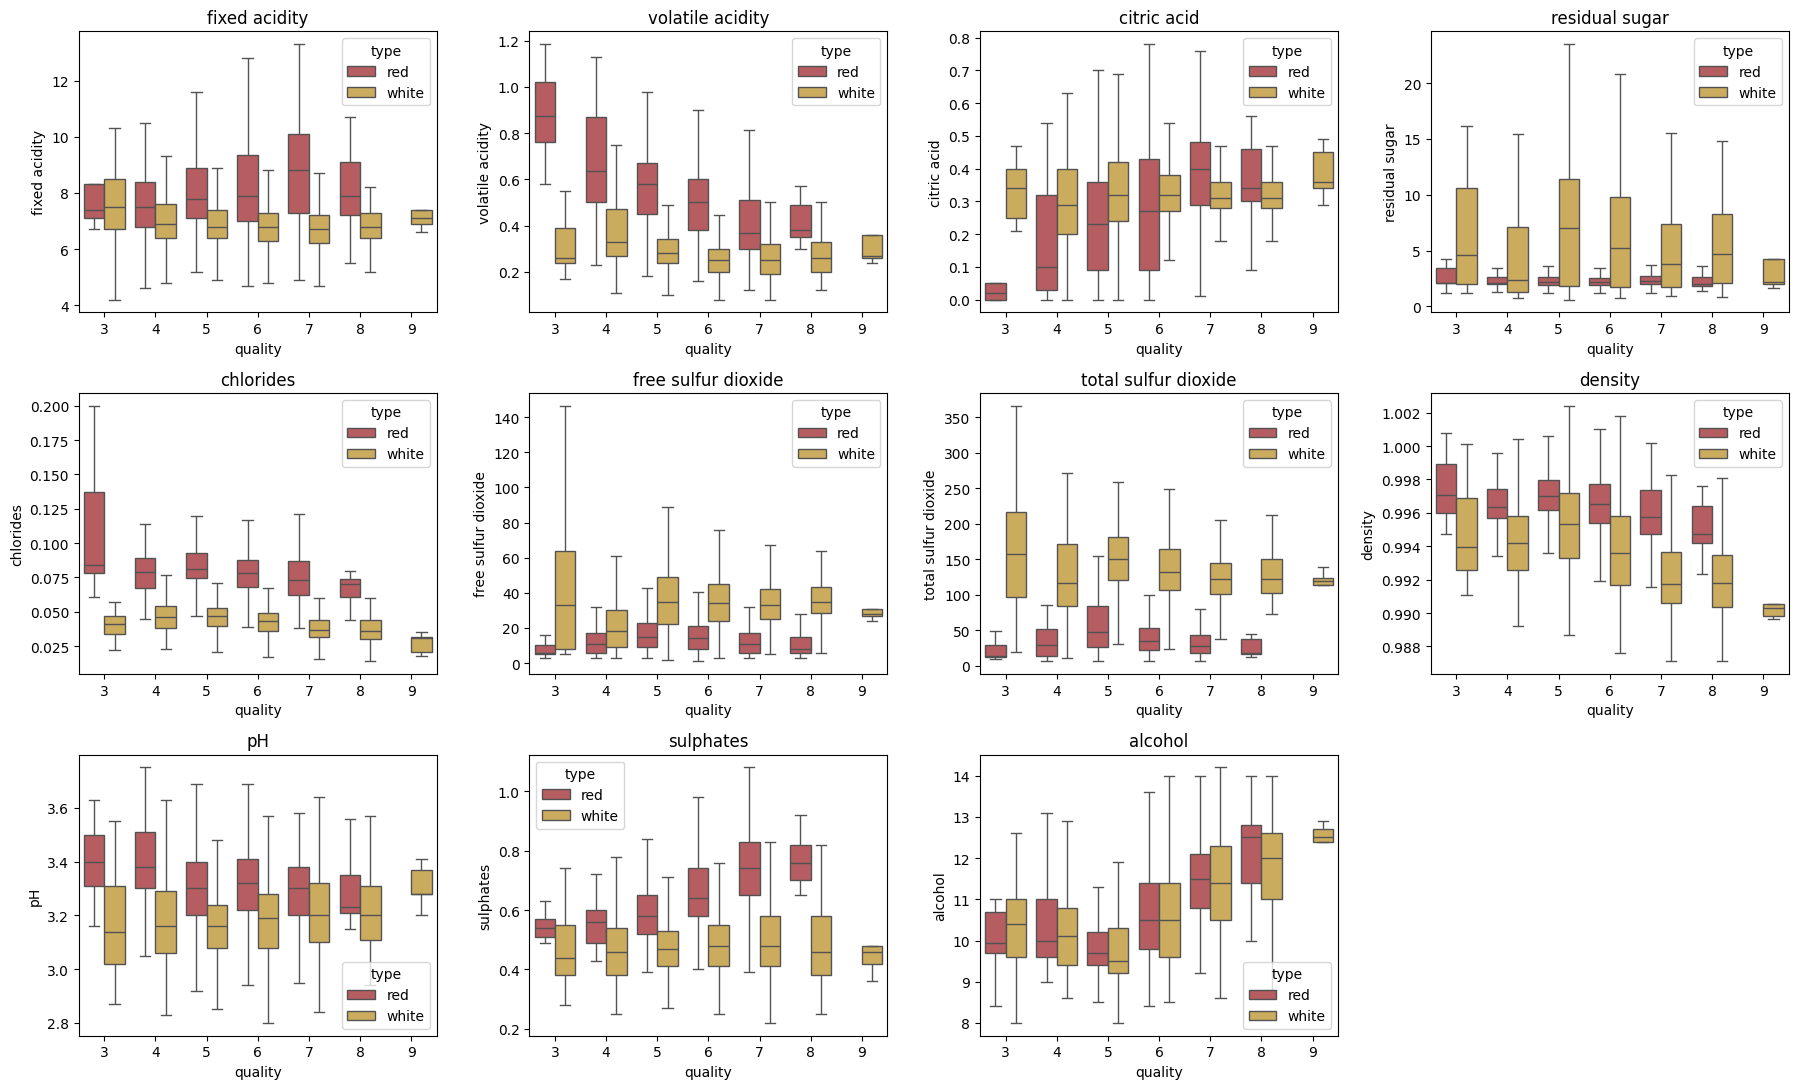

In [43]:
# 와인 종류(type)별로 품질 등급에 따른 변수 분포를 비교합니다.
type_name = train['type'].map({0: 'red', 1: 'white'})

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=train, x='quality', y=col, hue=type_name, ax=ax, showfliers=False,
                palette={'red': '#C44E52', 'white': '#DDB24C'})
    ax.set_title(col)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

## 등급 그룹 비교

In [44]:
quality_group = pd.cut(train['quality'], bins=[2, 4, 6, 9], labels=['low(3-4)', 'mid(5-6)', 'high(7-9)'])

group_median = train.groupby(quality_group, observed=True)[key_features].median()
group_median['count'] = quality_group.value_counts()
group_median

,alcohol,density,volatile acidity,chlorides,count
quality,,,,,
low(3-4),10.05,0.994940,0.380,0.050,212
mid(5-6),10.00,0.995385,0.295,0.049,4204
high(7-9),11.50,0.992300,0.280,0.039,1081


#모델링 준비

## 중복을 고려한 교차검증 (확인)

In [45]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.ensemble import ExtraTreesClassifier

X = train.drop(columns='quality')
y = train['quality']
groups = train.groupby(list(features) + ['type']).ngroup()

model = ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

normal_score = cross_val_score(model, X, y, cv=skf)
group_score = cross_val_score(model, X, y, cv=sgkf, groups=groups)
print(f'일반 5-Fold      : {normal_score.mean():.4f} ± {normal_score.std():.4f}')
print(f'중복 고려 5-Fold : {group_score.mean():.4f} ± {group_score.std():.4f}')

일반 5-Fold      : 0.6765 ± 0.0087
중복 고려 5-Fold : 0.5758 ± 0.0143


## 파생 변수 비교

In [46]:
def add_features(df):
    df = df.copy()
    df['bound_so2'] = df['total sulfur dioxide'] - df['free sulfur dioxide']
    df['alcohol_density'] = df['alcohol'] / df['density']
    df['volatile_ratio'] = df['volatile acidity'] / (df['fixed acidity'] + df['volatile acidity'])
    for col in ['volatile acidity', 'sulphates', 'citric acid']:
        df[f'{col}_red'] = df[col] * (df['type'] == 0)
    for col in features:
        df[f'{col}_rel'] = df[col] - df.groupby('type')[col].transform('median')
    return df

X_all = add_features(X)

def compare_features(candidates):
    results = {}
    for name, cols in candidates.items():
        X_cand = X_all[list(X.columns) + cols]
        normal = cross_val_score(model, X_cand, y, cv=skf)
        group = cross_val_score(model, X_cand, y, cv=sgkf, groups=groups)
        results[name] = [normal.mean(), group.mean(), group.std()]
    result_df = pd.DataFrame(results, index=['normal_cv', 'group_cv', 'group_std']).T
    result_df['group_gain'] = result_df['group_cv'] - result_df.loc['baseline', 'group_cv']
    return result_df.round(4)

## 파생 변수 재검증 (확인)

In [47]:
compare_features({
    'baseline': [],
    'bound_so2': ['bound_so2'],
    'alcohol_density': ['alcohol_density'],
})

,normal_cv,group_cv,group_std,group_gain
baseline,0.6765,0.5758,0.0143,0.0000
bound_so2,0.6798,0.5745,0.0098,-0.0013
alcohol_density,0.6742,0.5758,0.0104,-0.0000


## EDA 기반 파생 변수 비교

In [ ]:
compare_features({
    'baseline': [],
    'volatile_ratio': ['volatile_ratio'],
    'red_interaction': ['volatile acidity_red', 'sulphates_red', 'citric acid_red'],
    'type_relative': [f'{col}_rel' for col in features],
})